<a href="https://colab.research.google.com/github/bleojuandra26/ML-Seminar-BleojuAndra/blob/main/Bleoju_Andra-tema_laborator_3_ml.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Temă LP3 — Preprocesarea datelor (Titanic)

**Timp de lucru: maximum 15 minute** · lucru individual

Aplicați tehnicile din LP3 pe un set de date nou: **Titanic** — informații despre pasagerii navei (vârstă, sex, preț bilet, port de îmbarcare, punte) și dacă au supraviețuit (`survived`).

| Sarcina | Tema | Timp |
| --- | --- | --- |
| 1 | Valori lipsă: diagnostic și eliminare pe bază de prag | ~3 min |
| 2 | Imputarea valorilor lipsă | ~3 min |
| 3 | Asimetrie și transformare logaritmică | ~3 min |
| 4 | Outlieri (regula IQR) | ~3 min |
| 5 | Encoding și scalare | ~3 min |

> 💡 Completați celulele marcate `# TODO`. Nu e nevoie de cod perfect — contează să înțelegeți ce face fiecare pas.

### Pregătire — rulați celula (nu necesită modificări)

In [84]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
import warnings
warnings.filterwarnings('ignore')

titanic = sns.load_dataset('titanic')
df = titanic[['survived', 'pclass', 'sex', 'age', 'fare', 'embarked', 'deck']].copy()
df.head()


,survived,pclass,sex,age,fare,embarked,deck
0,0,3,male,22.0,7.2500,S,NaN
1,1,1,female,38.0,71.2833,C,C
2,1,3,female,26.0,7.9250,S,NaN
3,1,1,female,35.0,53.1000,S,C
4,0,3,male,35.0,8.0500,S,NaN


## Sarcina 1 — Valori lipsă (~3 min)

**1.1** Calculați procentul de valori lipsă pentru fiecare coloană, sortat descrescător.

**1.2** Eliminați coloanele cu **mai mult de 50%** valori lipsă. Care coloană dispare?

In [85]:
# TODO 1.1 — procentul de valori lipsă pe coloană
print((df.isnull().mean()*100).round(2).sort_values(ascending=False))

# TODO 1.2 — eliminați coloanele cu > 50% valori lipsă
def drop_columns_with_high_nulls(df, threshold_percentage):
    threshold = len(df) * (threshold_percentage / 100)
    dropped_columns = df.columns[df.isnull().sum() > threshold]
    df_cleaned = df.drop(columns=dropped_columns)
    return df_cleaned, dropped_columns

df, dropped = drop_columns_with_high_nulls(df, 50)

print("Coloane eliminate:", list(dropped))
print(df.head())

deck        77.22
age         19.87
embarked     0.22
sex          0.00
pclass       0.00
survived     0.00
fare         0.00
dtype: float64
Coloane eliminate: ['deck']
   survived  pclass     sex   age     fare embarked
0         0       3    male  22.0   7.2500        S
1         1       1  female  38.0  71.2833        C
2         1       3  female  26.0   7.9250        S
3         1       1  female  35.0  53.1000        S
4         0       3    male  35.0   8.0500        S


## Sarcina 2 — Imputarea valorilor lipsă (~3 min)

**2.1** Imputați `age` cu **mediana** și `embarked` cu **valoarea cea mai frecventă** (modul).

**2.2** Verificați că nu mai există valori lipsă și comparați deviația standard a lui `age` înainte și după imputare. *(salvați înainte de imputare: `age_inainte = df['age'].copy()`)*

In [86]:
# TODO 2.1 — imputare age (mediană) și embarked (mod)
age_inainte = df['age'].copy()
print(age_inainte.isnull().sum())
age_mediana = pd.DataFrame(SimpleImputer(strategy='median').fit_transform(df[['age']]),columns=['age'])
df['age'] = age_mediana['age']
print(df['age'].isnull().sum())

embarked_mod = pd.DataFrame( SimpleImputer(strategy='most_frequent').fit_transform(df[['embarked']]),columns=['embarked'])
df['embarked'] = embarked_mod['embarked']
print(df['embarked'].isnull().sum())
# TODO 2.2 — verificare + comparație deviație standard
print("Lipsă înainte:", age_inainte.isnull().sum())
print("Lipsă după:", df['age'].isnull().sum())
print("Înainte:", age_inainte.std())
print("După:", df['age'].std())

177
0
0
Lipsă înainte: 177
Lipsă după: 0
Înainte: 14.526497332334044
După: 13.019696550973194


## Sarcina 3 — Asimetrie și transformare logaritmică (~3 min)

**3.1** Calculați skewness-ul variabilei `fare`.

**3.2** Creați coloana `log_fare = np.log1p(fare)` și calculați skewness-ul ei. A ajutat transformarea?

**3.3** Desenați cele două histograme una lângă alta.

4.787316519674893
0.3949280095189306


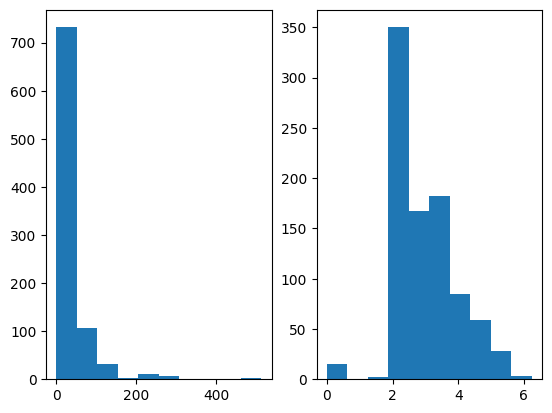

In [87]:
# TODO 3.1 — skewness fare
s = df['fare'].skew()
print(s)
# TODO 3.2 — coloana log_fare + skewness
df['log_fare'] = np.log1p(df['fare'])
skeness = log_fare.skew()
print(skeness)
# TODO 3.3 — două histograme
plt.subplot(1, 2, 1)
plt.hist(df['fare'])

plt.subplot(1, 2, 2)
plt.hist(df['log_fare'])

plt.show()

## Sarcina 4 — Outlieri cu regula IQR (~3 min)

**4.1** Calculați limitele `[Q1 − 1,5·IQR ; Q3 + 1,5·IQR]` pentru `fare` și numărați outlierii.

**4.2** Limitați (clip) valorile extreme într-o coloană nouă, `fare_capped`, și afișați maximul înainte și după.

In [88]:
# TODO 4.1 — limite IQR + număr de outlieri
q1 = df['fare'].quantile(0.25)
q3 = df['fare'].quantile(0.75)
IQR = q3-q1
lim_inf = q1-1.5*IQR
lim_sup = q3+1.5*IQR
print(lim_inf , lim_sup)
outlieri = ((df['fare'] < lim_inf) | (df['fare'] > lim_sup)).sum()
print("Număr outlieri:", outlieri)
# TODO 4.2 — fare_capped (clip) + maxim înainte/după
df['fare_capped'] = df['fare'].clip(lower=lim_inf, upper=lim_sup)
print("Maxim înainte:", df['fare'].max())
print("Maxim după:", df['fare_capped'].max())

-26.724 65.6344
Număr outlieri: 116
Maxim înainte: 512.3292
Maxim după: 65.6344


## Sarcina 5 — Encoding și scalare (~3 min)

**5.1** Aplicați One-Hot Encoding pe `sex` și `embarked` (cu `drop_first=True`, `dtype=int`).

**5.2** Standardizați `age` și `fare_capped` cu `StandardScaler`. Verificați că media ≈ 0 și deviația standard ≈ 1.

In [89]:
from sys import float_repr_style
# TODO 5.1 — One-Hot Encoding pentru sex și embarked
cate_sex = pd.get_dummies(df['sex'], drop_first=True, dtype=int)
print(cate_sex)

cate_embarked = pd.get_dummies(df['embarked'], drop_first=True, dtype=int)
print(cate_embarked)
# TODO 5.2 — StandardScaler pentru age și fare_capped + verificare medie/std
age_std = pd.DataFrame(StandardScaler().fit_transform(df[['age']]),columns=['age_std'])
print(age_std.head())
fare_capped_std = pd.DataFrame(StandardScaler().fit_transform(df[['fare_capped']]),columns=['fare_capped'])
print(fare_capped_std.head())

print(age_std.mean())
print(age_std.std(ddof=0))

print(fare_capped_std.mean())
print(fare_capped_std.std(ddof=0))

     male
0       1
1       0
2       0
3       0
4       1
..    ...
886     1
887     0
888     0
889     1
890     1

[891 rows x 1 columns]
     Q  S
0    0  1
1    0  0
2    0  1
3    0  1
4    0  1
..  .. ..
886  0  1
887  0  1
888  0  1
889  0  0
890  1  0

[891 rows x 2 columns]
    age_std
0 -0.565736
1  0.663861
2 -0.258337
3  0.433312
4  0.433312
   fare_capped
0    -0.820552
1     2.031623
2    -0.787578
3     1.419297
4    -0.781471
age_std    2.272780e-16
dtype: float64
age_std    1.0
dtype: float64
fare_capped    9.968332e-17
dtype: float64
fare_capped    1.0
dtype: float64


## Întrebare de reflecție (1–2 propoziții)

*De ce am imputat `age`, dar am eliminat `deck`?*

Răspunsul tău: Am imputat valorile lipsă din age deoarece această coloană conține informații importante și are un procent relativ mic de valori lipsă. Am eliminat deck deoarece majoritatea valorilor sunt lipsă, iar imputarea lor ar putea introduce informații inexacte.